# How a GPT works, from scratch

*A guided tour you can run. By the end, a model you trained yourself on this machine writes sentences — and you will have built every part of it.*

### What this notebook is

A GPT is not one clever trick. It is about six simple ideas, stacked and repeated. This notebook builds all of them in plain Python + NumPy (~200 lines, no PyTorch), trains the result, and shows pictures of what it learned.

The model here has **14,464 parameters**. GPT-4 has something on the order of a trillion. The recipe is identical — only the numbers change. That is the most useful single fact in this notebook.

### What you need to know already

Python, and roughly what a matrix is. Every other piece of maths is introduced where it is used.

### The route

| Part | Question it answers |
|---|---|
| 1. The only job | What is a GPT actually trained to do? |
| 2. Tokens | How does text become numbers? |
| 3. Embeddings | How does a number become meaning? |
| 4. Attention | How does one word look at the others? *(the heart of it)* |
| 5. The block | What else is inside besides attention? |
| 6. Autograd | How does any of this learn? |
| 7. Training | Watching the loss fall |
| 8. Generation | From predictor to writer, and what "temperature" means |
| 9. Inside the trained model | The pictures |
| 10. Scaling | From 14k parameters to GPT-4 |
| 11. Limits | What this explains, and what it does not |

### Honest framing, up front

A GPT is a **very good next-token predictor**. Everything people describe it as doing — translating, coding, arithmetic, "reasoning" — is a side effect of getting extremely good at that one task. Whether next-token prediction deserves to be called *understanding* is a live scientific and philosophical question. This notebook shows you exactly what the machine does, so you can place that line yourself.

## Part 1 — The only job: predict the next token

Strip away the interface. A language model receives text and outputs **a probability for every possible next token**.

If the text so far is the tokens $x_1, \dots, x_t$, the model computes

$$p(x_{t+1} \mid x_1, \dots, x_t)$$

That is the entire output: a list of probabilities, one per token in the vocabulary. The model is not looking up a fact, not running a program, not planning. It is answering one question: *given these tokens, what plausibly comes next?*

Sit with that for a second, because a surprising amount of apparent intelligence fits inside it.

### How "getting good at it" is measured

When the true next token is $x_{t+1}$ and the model assigned it probability $p$, the model's **surprise** is

$$-\log_2 p \quad \text{bits}$$

- probability 1.0 on the right answer → 0 bits of surprise;
- probability spread evenly over 100 options and the right one was among them → $-\log_2 0.01 \approx 6.6$ bits;
- probability ~0 on the right answer → enormous surprise.

Training means **making the average surprise small on real text**. That average is the *loss*, and every number in a training log is a version of it.

Note the consequence: a model that is 90% right and knows it is worth more than one that is 60% right and confident. Confidence is scored, not just correctness. This is the seed of a lot of later behaviour, good and bad.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Illustrative numbers: how a trained model might distribute probability.
# What matters is the last column, not the exact values.
examples = [
    ("The capital of France is",   "Paris",  0.92),
    ("2 + 2 =",                    "4",      0.99),
    ("She poured water into the",  "glass",  0.31),
    ("The cat sat on the",         "mat",    0.44),
    ("I'd like a cup of",          "coffee", 0.18),
]

df = pd.DataFrame(
    [(ctx, nxt, p, round(-np.log2(p), 2)) for ctx, nxt, p in examples],
    columns=["tokens so far", "true next token", "model's probability", "surprise (bits)"],
)
print(f"average surprise: {df['surprise (bits)'].mean():.2f} bits per token")
df

average surprise: 1.09 bits per token


,tokens so far,true next token,model's probability,surprise (bits)
0,The capital of France is,Paris,0.92,0.12
1,2 + 2 =,4,0.99,0.01
2,She poured water into the,glass,0.31,1.69
3,The cat sat on the,mat,0.44,1.18
4,I'd like a cup of,coffee,0.18,2.47


## Part 2 — Tokens: text becomes integers

A neural network cannot take letters. So text is chopped into **tokens**, and each token gets an integer id.

Real GPTs use *byte-pair encoding*: frequent chunks of characters become single tokens. "unbelievably" is roughly `un` + `believ` + `ably` — three tokens, not twelve. A modern vocabulary is 50,000–200,000 tokens. Two consequences worth knowing:

- **Rare words cost more tokens.** "anthropomorphize" might be 4 tokens; that is 4 prediction steps, and more chance for one to go wrong.
- **The model never sees characters.** It sees ids. This is why models miscount letters in a word — ask "how many r's in strawberry" and the model is reasoning about a token, not letters. (In our toy model below, tokens *are* characters, so it would find the r's fine. That is a useful contrast.)

Our vocabulary is 21 symbols: the letters used in a handful of small sentences, a space, and a full stop. Small enough to see everything.

In [15]:
rng = np.random.default_rng(0)

# A toy "language": three slots, so the model can learn grammar-like structure.
subj  = ['cat', 'dog', 'fox', 'owl']
verb  = ['sat', 'ran', 'slept', 'hid']
place = ['mat', 'log', 'box', 'tree']
text = "".join(
    f"the {rng.choice(subj)} {rng.choice(verb)} on the {rng.choice(place)}. "
    for _ in range(60)
)

chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}   # string -> id
itos = {i: c for c, i in stoi.items()}       # id -> string
data = np.array([stoi[c] for c in text])

V = len(chars)   # vocabulary size
N = len(data)    # corpus length

print(f"corpus: {N} characters, vocabulary: {V} symbols")
print("text starts:", repr(text[:72]))
print()
print("the vocabulary:", "".join(chars))
print("encode('the cat'):", [stoi[c] for c in "the cat"])
print("decode(...)      :", repr("".join(itos[i] for i in [stoi[c] for c in "the cat"])))
print()
pd.DataFrame({"id": range(V), "token": [repr(c) for c in chars]}).set_index("id").T

corpus: 1482 characters, vocabulary: 21 symbols
text starts: 'the owl slept on the box. the dog ran on the mat. the cat sat on the mat'

the vocabulary:  .abcdefghilmnoprstwx
encode('the cat'): [18, 9, 6, 0, 4, 2, 18]
decode(...)      : 'the cat'



id,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
token,' ','.','a','b','c','d','e','f','g','h',...,'l','m','n','o','p','r','s','t','w','x'


## Part 3 — Embeddings: an id becomes a point in space

An id like `7` is arbitrary. It carries no meaning, and nothing in it says that `7` and `8` are neighbours while `7` and `19` are not.

So each id is mapped to a **learned vector of numbers** — here 32 numbers per token. That vector is the token's *embedding*: its position in a 32-dimensional space. The model works entirely with these vectors.

The famous line for why this works (Firth, 1957): **"you shall know a word by the company it keeps."** Tokens appearing in similar contexts get pushed toward similar vectors, because that is what helps predict what comes next. Nobody designs the geometry — gradient descent discovers it.

- This notebook: 21 tokens × 32 dimensions.
- GPT-3: 50,257 tokens × 12,288 dimensions.

### Why a *position* embedding is also needed

Here is the strange part: attention (next part) is **order-blind**. It treats its inputs as a bag. "dog bites man" and "man bites dog" would be identical to it. So a second vector, one per *position* 0, 1, 2, …, is added to each token's vector. That is the only thing in the whole model that knows about order.

The two are simply added: `vector(token) + vector(position)`.

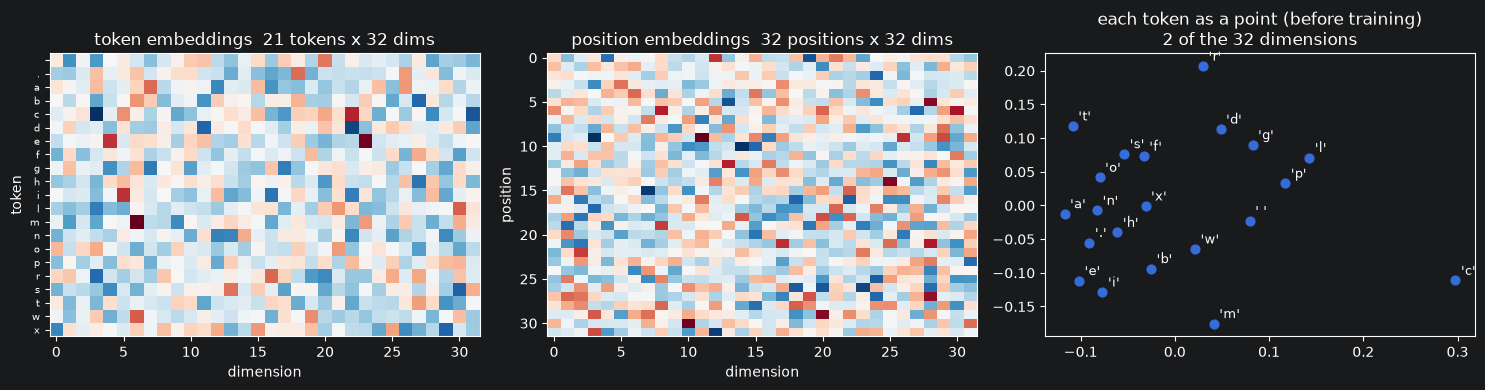

Before training the vectors are random noise: no structure, no meaning.
We will look at this same plot after training.


In [16]:
d   = 32   # how many numbers describe one token
blk = 32   # how many tokens the model sees at once (its "context window")

tok_emb = rng.normal(0, 0.05, (V, d))     # one row per token  (V x 32)
pos_emb = rng.normal(0, 0.01, (blk, d))   # one row per position (32 x 32)

E_before = tok_emb.copy()   # keep the untrained version, we compare later

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(tok_emb, cmap="RdBu", aspect="auto")
ax[0].set_title(f"token embeddings  {V} tokens x {d} dims")
ax[0].set_xlabel("dimension"); ax[0].set_ylabel("token")
ax[0].set_yticks(range(V)); ax[0].set_yticklabels(chars, fontsize=7)

ax[1].imshow(pos_emb, cmap="RdBu", aspect="auto")
ax[1].set_title(f"position embeddings  {blk} positions x {d} dims")
ax[1].set_xlabel("dimension"); ax[1].set_ylabel("position")

# squash 32 numbers down to 2 so we can look at them
U, S, Vt = np.linalg.svd(tok_emb - tok_emb.mean(0), full_matrices=False)
xy = U[:, :2] * S[:2]
ax[2].scatter(xy[:, 0], xy[:, 1], s=40)
for i, c in enumerate(chars):
    ax[2].annotate(repr(c), (xy[i, 0], xy[i, 1]), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax[2].set_title("each token as a point (before training)\n2 of the 32 dimensions")
plt.tight_layout(); plt.show()

print("Before training the vectors are random noise: no structure, no meaning.")
print("We will look at this same plot after training.")

## Part 4 — Attention: how a token looks at the others

Consider:

> *The trophy would not fit in the suitcase because **it** was too big.*

What does "it" refer to? You resolved that instantly, using the earlier words. **Attention is the mechanism that lets a token do exactly that: look back and pull in information from other tokens.**

### The library analogy

For the token being processed (the *query*), the model asks:

- **Query (Q)** — what am I looking for? ("I am a pronoun; I need a noun.")
- **Key (K)** — what do I advertise? Every earlier token publishes a key. ("I am a noun, a large object.")
- **Value (V)** — what do I actually hand over? The content itself.

Matching query against keys gives a **relevance score** for each earlier token. Those scores, turned into weights that sum to 1, are used to take a **weighted average of the value vectors**. That weighted average is what the current token receives.

In one line: **attention is a learned, weighted average over the past.**

### The formula

For one head, and $d$ = the width of a vector:

$$\text{scores} = \frac{Q K^\top}{\sqrt{d}}, \qquad
\text{weights} = \operatorname{softmax}(\text{masked scores over allowed positions}), \qquad
\text{output} = \text{weights} \cdot V$$

$Q = XW_Q$, $K = XW_K$, $V = XW_V$ — the same token vectors $X$, projected three different ways by three learned matrices. That's all the "three projections" are.

Every part of this formula has a reason, and each gets its own explanation two cells down. First, run it by hand.

tokens      : ['t', 'h', 'e', ' ', 'c', 'a']
X shape     : (6, 32)   scores shape: (6, 6)

one row of weights, for token 'a' :
   reads 0.209 of 't'
   reads 0.233 of 'h'
   reads 0.132 of 'e'
   reads 0.183 of ' '
   reads 0.088 of 'c'
   reads 0.155 of 'a'


Notice: these weights are close to uniform. Untrained attention is almost a plain
average of everything before it -- the scores barely differ, so softmax flattens out.
Attention starts as 'listen to everyone equally'; training is what makes it selective.

output shape: (6, 32) -- same shape as the input, so layers can stack


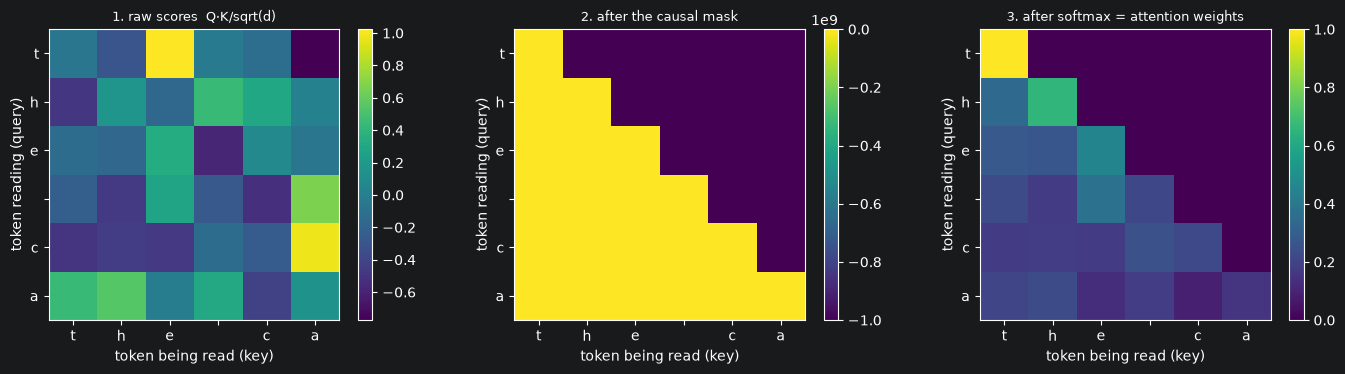

In [17]:
# Run attention by hand on six tokens, with random (untrained) weights.
# The pattern will be meaningless -- the point is the machinery.
tokens = list("the ca")
ids    = [stoi[c] for c in tokens]
n      = len(ids)
X      = tok_emb[ids]                        # (n, d)  the token vectors

Wq = rng.normal(0, 2.0, (d, d))   # untrained weights, deliberately on the wide side
Wk = rng.normal(0, 2.0, (d, d))
Wv = rng.normal(0, 2.0, (d, d))

Q = X @ Wq                                   # what each token is looking for
K = X @ Wk                                   # what each token offers
Vv = X @ Wv                                  # what each token hands over

scores = Q @ K.T / np.sqrt(d)                # (n, n): every query vs every key
mask   = np.triu(np.ones((n, n), dtype=bool), 1)   # True above the diagonal
masked = np.where(mask, -1e9, scores)        # forbidden = effectively minus infinity
e      = np.exp(masked - masked.max(1, keepdims=True))
weights = e / e.sum(1, keepdims=True)        # each row sums to 1
out    = weights @ Vv                        # each token's new vector

print("tokens      :", tokens)
print("X shape     :", X.shape, "  scores shape:", scores.shape)
print()
print("one row of weights, for token", repr(tokens[-1]), ":")
for j, w in enumerate(weights[-1]):
    print(f"   reads {w:5.3f} of {tokens[j]!r}")
print()
print()
print("Notice: these weights are close to uniform. Untrained attention is almost a plain")
print("average of everything before it -- the scores barely differ, so softmax flattens out.")
print("Attention starts as 'listen to everyone equally'; training is what makes it selective.")
print()
print("output shape:", out.shape, "-- same shape as the input, so layers can stack")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, M, t in [(ax[0], scores, "1. raw scores  Q·K/sqrt(d)"),
                (ax[1], masked, "2. after the causal mask"),
                (ax[2], weights, "3. after softmax = attention weights")]:
    im = a.imshow(M, cmap="viridis")
    a.set_xticks(range(n)); a.set_xticklabels(tokens)
    a.set_yticks(range(n)); a.set_yticklabels(tokens)
    a.set_title(t, fontsize=9)
    a.set_xlabel("token being read (key)"); a.set_ylabel("token reading (query)")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

### Written out, number by number

The last cell used 32 dimensions, which does not fit on a screen — and numbers you cannot read teach nothing. So here is **the identical calculation at width 4**, on three tokens, with every matrix printed in full.

Nothing changes except the width. Each step below is exactly one line of the formula from earlier:

$$X \;\to\; Q = XW_Q,\; K = XW_K,\; V = XW_V \;\to\; \text{scores} = \frac{QK^\top}{\sqrt{d}} \;\to\; \text{mask} \;\to\; \text{softmax} \;\to\; \text{out} = \text{weights}\cdot V$$

(One honest note about what you are looking at: the token vectors $X$ below are rows of the real embedding table, cut to their first 4 numbers and scaled by a constant so the numbers are readable in a table. The little 4×4 weight matrices are fresh random draws, because the model's real ones are 32×32. Scaling all vectors by one constant changes nothing about the mechanism, and the number of columns changes nothing about the arithmetic.)

In [18]:
try:                                  # rich tables in Jupyter...
    from IPython.display import display
except Exception:                     # ...and plain text if run as a script
    def display(obj):
        print(obj)

def show(M, rows, cols, title):
    """Print a matrix with its labels, so you can see what every entry is."""
    print(title)
    display(pd.DataFrame(M, index=rows, columns=cols).round(3))

toks = ["t", "h", "e"]        # three tokens -- in this notebook a token is one character
ids3 = [stoi[c] for c in toks]
w    = 4                      # 4 numbers per token, for readability

X = tok_emb[ids3, :w]         # (3 tokens, 4 dims) -- rows of the real embedding table
X = X / np.abs(X).max()       # scaled so the numbers below are readable on screen;
                              # multiplying every vector by one constant changes nothing
dims = [f"dim{i}" for i in range(w)]
show(X, toks, dims, "STEP 0 — X: each token is a row of 4 numbers (here we write 'the', one letter at a time)")

STEP 0 — X: each token is a row of 4 numbers (here we write 'the', one letter at a time)


,dim0,dim1,dim2,dim3
t,-0.647,0.964,-0.125,0.999
h,0.811,0.618,0.195,1.000
e,0.389,-0.322,-0.190,-0.456


In [19]:
rng2 = np.random.default_rng(42)             # a separate generator, so re-running is stable
Wq = rng2.normal(0, 1.5, (w, w))
Wk = rng2.normal(0, 1.5, (w, w))
Wv = rng2.normal(0, 1.5, (w, w))
show(Wq, dims, ["-> dim0", "-> dim1", "-> dim2", "-> dim3"],
     "STEP 1 — W_Q: the learned matrix that turns a token vector into a query\n"
     "         rows = the 4 numbers coming in, columns = the 4 numbers going out")

Q = X @ Wq                                   # (3,4) @ (4,4) -> (3,4)
show(Q, toks, dims, "STEP 2 — Q = X @ W_Q      (3x4) @ (4x4)  ->  (3x4)")

print("What one entry actually is: a dot product of one row of X with one column of W_Q.")
i, j = 1, 2                                  # token 'h', output number 2
terms = " + ".join(f"({X[i, k]:.3f} x {Wq[k, j]:.3f})" for k in range(w))
print(f"  Q[h, dim2] = {terms}")
print(f"             = {sum(X[i, k] * Wq[k, j] for k in range(w)):.4f}"
      f"   <- matches Q[1,2] = {Q[i, j]:.4f}")
print()
print("Nothing else is happening. Every entry of every matrix in this notebook is a")
print("multiply-and-add like that one: pick a row, pick a column, multiply pairs, sum.")

STEP 1 — W_Q: the learned matrix that turns a token vector into a query
         rows = the 4 numbers coming in, columns = the 4 numbers going out


,-> dim0,-> dim1,-> dim2,-> dim3
dim0,0.457,-1.560,1.126,1.411
dim1,-2.927,-1.953,0.192,-0.474
dim2,-0.025,-1.280,1.319,1.167
dim3,0.099,1.691,0.701,-1.289


STEP 2 — Q = X @ W_Q      (3x4) @ (4x4)  ->  (3x4)


,dim0,dim1,dim2,dim3
t,-3.014,0.976,-0.008,-2.803
h,-1.345,-1.032,1.990,-0.211
e,1.080,-0.504,-0.194,1.067


What one entry actually is: a dot product of one row of X with one column of W_Q.
  Q[h, dim2] = (0.811 x 1.126) + (0.618 x 0.192) + (0.195 x 1.319) + (1.000 x 0.701)
             = 1.9899   <- matches Q[1,2] = 1.9899

Nothing else is happening. Every entry of every matrix in this notebook is a
multiply-and-add like that one: pick a row, pick a column, multiply pairs, sum.


In [20]:
# ('Vv' not 'V': V is the vocabulary size, and it must not be overwritten)
K  = X @ Wk
Vv = X @ Wv
show(K, toks, dims, "STEP 3 — K = X @ W_K      what each token advertises")
show(Vv, toks, dims, "STEP 4 — V = X @ W_V      what each token hands over if chosen")

scores = Q @ K.T / np.sqrt(w)
show(scores, [f"query: {c}" for c in toks], [f"key: {c}" for c in toks],
     "STEP 5 — scores = Q @ K^T / sqrt(4)      (3x4) @ (4x3) -> (3x3)")
print("Read a row as: how strongly does THIS token want to read each earlier token?")
print(f"  scores[h, t] = Q[h] . K[t] / 2 = {scores[1, 0]:.4f}")
print()
print("Note the shape: square, one row per token, one column per token. This is the")
print("3x3 (in the real model: 32x32) grid of 'who looks at whom'.")

STEP 3 — K = X @ W_K      what each token advertises


,dim0,dim1,dim2,dim3
t,0.073,0.658,4.024,-0.852
h,0.771,-1.255,5.571,-0.707
e,0.144,-0.424,-1.694,0.219


STEP 4 — V = X @ W_V      what each token hands over if chosen


,dim0,dim1,dim2,dim3
t,0.368,-0.199,-0.359,0.136
h,-0.336,-1.282,1.097,2.380
e,-0.535,-0.372,0.352,0.125


STEP 5 — scores = Q @ K^T / sqrt(4)      (3x4) @ (4x3) -> (3x3)


,key: t,key: h,key: e
query: t,1.389,-0.805,-0.725
query: h,3.704,5.746,-1.587
query: e,-0.972,-0.185,0.466


Read a row as: how strongly does THIS token want to read each earlier token?
  scores[h, t] = Q[h] . K[t] / 2 = 3.7044

Note the shape: square, one row per token, one column per token. This is the
3x3 (in the real model: 32x32) grid of 'who looks at whom'.


In [21]:
allowed = np.tril(np.ones((3, 3), dtype=bool))   # True = allowed to look
show(allowed.astype(int), [f"query: {c}" for c in toks], [f"key: {c}" for c in toks],
     "STEP 6 — the mask: 1 = may read, 0 = forbidden (the future)")
print("The upper right is all zeros: 't' may not read 'h' or 'e'; 'h' may not read 'e'.")
print("A token can only read itself and things before it.")
print()

masked = np.where(allowed, scores, -np.inf)
show(masked, [f"query: {c}" for c in toks], [f"key: {c}" for c in toks],
     "STEP 7 — scores with the forbidden entries set to -infinity")

e = np.exp(masked - masked.max(axis=1, keepdims=True))   # -inf -> 0
show(e, [f"query: {c}" for c in toks], [f"key: {c}" for c in toks],
     "STEP 8 — e^score, row by row   (e^-infinity = 0: that is how the mask deletes things)")

weights = e / e.sum(axis=1, keepdims=True)
show(weights, [f"query: {c}" for c in toks], [f"key: {c}" for c in toks],
     "STEP 9 — divide each row by its sum  ->  attention weights, every row adds to 1.000")
print("row sums:", np.round(weights.sum(axis=1), 6))

STEP 6 — the mask: 1 = may read, 0 = forbidden (the future)


,key: t,key: h,key: e
query: t,1,0,0
query: h,1,1,0
query: e,1,1,1


The upper right is all zeros: 't' may not read 'h' or 'e'; 'h' may not read 'e'.
A token can only read itself and things before it.

STEP 7 — scores with the forbidden entries set to -infinity


,key: t,key: h,key: e
query: t,1.389,-inf,-inf
query: h,3.704,5.746,-inf
query: e,-0.972,-0.185,0.466


STEP 8 — e^score, row by row   (e^-infinity = 0: that is how the mask deletes things)


,key: t,key: h,key: e
query: t,1.000,0.000,0.0
query: h,0.130,1.000,0.0
query: e,0.237,0.521,1.0


STEP 9 — divide each row by its sum  ->  attention weights, every row adds to 1.000


,key: t,key: h,key: e
query: t,1.000,0.000,0.000
query: h,0.115,0.885,0.000
query: e,0.135,0.296,0.569


row sums: [1. 1. 1.]


In [22]:
out = weights @ Vv
show(out, toks, dims, "STEP 10 — out = weights @ V      (3x3) @ (3x4) -> (3x4)")

print("The last token, 'e', has weights", np.round(weights[2], 3), "over ['t', 'h', 'e'].")
print("So its output row is a blend of the three value rows, in those proportions:")
for k, c in enumerate(toks):
    print(f"   {weights[2, k]:.3f} x V[{c}] = {np.round(weights[2, k] * Vv[k], 3)}")
blend = sum(weights[2, k] * Vv[k] for k in range(3))
print(f"   {'sum':>17s} = {np.round(blend, 3)}   <- matches out[2] = {np.round(out[2], 3)}")
print()
print("That is attention, fully: each token replaces itself with a weighted average of")
print("the value vectors of the tokens it was allowed to read.")
print("Note the shape: (3,4) in, (3,4) out -- which is why these blocks can stack.")

STEP 10 — out = weights @ V      (3x3) @ (3x4) -> (3x4)


,dim0,dim1,dim2,dim3
t,0.368,-0.199,-0.359,0.136
h,-0.255,-1.158,0.930,2.122
e,-0.354,-0.619,0.476,0.795


The last token, 'e', has weights [0.135 0.296 0.569] over ['t', 'h', 'e'].
So its output row is a blend of the three value rows, in those proportions:
   0.135 x V[t] = [ 0.05  -0.027 -0.049  0.018]
   0.296 x V[h] = [-0.1   -0.38   0.325  0.705]
   0.569 x V[e] = [-0.304 -0.212  0.2    0.071]
                 sum = [-0.354 -0.619  0.476  0.795]   <- matches out[2] = [-0.354 -0.619  0.476  0.795]

That is attention, fully: each token replaces itself with a weighted average of
the value vectors of the tokens it was allowed to read.
Note the shape: (3,4) in, (3,4) out -- which is why these blocks can stack.


In [23]:
# ---- the rest of the block, equally written out -----------------------------------
left = X + out                               # residual: add, do not replace
show(left, toks, dims, "STEP 11 — residual: x = x + attention_out      (same shape, added element-wise)")
print("'e' was", np.round(X[2], 3), "and became", np.round(left[2], 3), "-- edited, not overwritten.")
print()

# ---- LayerNorm on one token, all four numbers visible
x    = left[2]                               # the token 'e'
mu   = x.mean()
sd   = np.sqrt(x.var() + 1e-5)
xhat = (x - mu) / sd
gamma = np.array([1.2, 0.8, 1.0, 1.5])       # learned scale
beta  = np.array([0.1, -0.2, 0.0, 0.3])      # learned shift
y = xhat * gamma + beta

table = pd.DataFrame({"x": x, "x - mean": x - mu, "/ std": xhat, "x gamma + beta": y},
                     index=dims).round(3)
print("STEP 12 — LayerNorm on token 'e':    mean =", round(mu, 3), "   std =", round(sd, 3))
display(table)
print("The 4 numbers are rescaled so they average 0 and spread 1, then gamma and beta")
print("(both learned) stretch and shift them to whatever size the next layer wants.")
print()

# ---- the MLP: two matrix multiplies with a ReLU in between
W1 = rng2.normal(0, 0.6, (w, 6))
b1 = rng2.normal(0, 0.1, 6)
W2 = rng2.normal(0, 0.6, (6, w))
b2 = rng2.normal(0, 0.1, w)

h = np.maximum(left @ W1 + b1, 0)            # (3,4) @ (4,6) -> (3,6); negatives killed
show(h, toks, [f"h{i}" for i in range(6)],
     "STEP 13 — MLP up: h = relu(x @ W1 + b1)      (3x4) @ (4x6) -> (3x6)")
print("relu(x) = max(x, 0): every negative entry becomes 0. That is the only nonlinearity")
print("in the block -- without it, stacking layers would just be one big matrix multiply.")
print()

x_final = h @ W2 + b2
show(x_final, toks, dims, "STEP 14 — MLP down: x = h @ W2 + b2      (3x6) @ (6x4) -> (3x4)")
print("Out in the same shape it came in (3 tokens x 4 dims): ready for the next block, or,")
print("if this was the last block, for the projection onto the vocabulary.")

STEP 11 — residual: x = x + attention_out      (same shape, added element-wise)


,dim0,dim1,dim2,dim3
t,-0.279,0.765,-0.484,1.135
h,0.556,-0.539,1.125,3.122
e,0.034,-0.941,0.287,0.339


'e' was [ 0.389 -0.322 -0.19  -0.456] and became [ 0.034 -0.941  0.287  0.339] -- edited, not overwritten.

STEP 12 — LayerNorm on token 'e':    mean = -0.07    std = 0.516


,x,x - mean,/ std,x gamma + beta
dim0,0.034,0.105,0.203,0.343
dim1,-0.941,-0.871,-1.688,-1.551
dim2,0.287,0.357,0.692,0.692
dim3,0.339,0.409,0.794,1.490


The 4 numbers are rescaled so they average 0 and spread 1, then gamma and beta
(both learned) stretch and shift them to whatever size the next layer wants.

STEP 13 — MLP up: h = relu(x @ W1 + b1)      (3x4) @ (4x6) -> (3x6)


,h0,h1,h2,h3,h4,h5
t,0.0,0.00,0.377,0.349,0.000,0.0
h,0.0,0.00,1.917,0.000,0.000,0.0
e,0.0,0.26,0.378,0.000,0.279,0.0


relu(x) = max(x, 0): every negative entry becomes 0. That is the only nonlinearity
in the block -- without it, stacking layers would just be one big matrix multiply.

STEP 14 — MLP down: x = h @ W2 + b2      (3x6) @ (6x4) -> (3x4)


,dim0,dim1,dim2,dim3
t,-0.002,0.056,-0.073,0.064
h,-0.575,0.088,0.460,0.493
e,-0.481,-0.225,-0.392,-0.010


Out in the same shape it came in (3 tokens x 4 dims): ready for the next block, or,
if this was the last block, for the projection onto the vocabulary.


### The four details that actually matter

**1. Why divide by $\sqrt{d}$?**
A dot product of two vectors with $d$ components adds up $d$ terms. The more dimensions, the larger the scores — and large scores push softmax into saturation, where it outputs nearly 1 and nearly 0, and the gradients vanish (nothing learns). Dividing by $\sqrt{d}$ keeps the scores in a workable range. Pure engineering, essential in practice.

**2. Why softmax?**
We need weights that are positive and sum to 1 — a proper weighted average. Softmax does that: $w_i = e^{s_i} / \sum_j e^{s_j}$. Note it is *winner-takes-more*: exponentials amplify differences, so a score slightly ahead gets a much larger weight. That is what makes attention able to be decisive rather than always blending everything.

**3. Why the causal mask?**
Look back at the weight matrix you computed (STEP 9), or the third heatmap: it is lower-triangular. Position 5 may read positions 0–5, never 6 or later. Why? **Because the model is being trained to predict the next token.** If position $t$ could see token $t+1$, the answer would be right there in its input, and it would learn to copy instead of predict. The mask enforces: *only the past, never the future.* This is what the G in **GPT** — *generative pre-trained transformer* — commits to.

**4. Why the mask also makes training fast.**
Because of the mask, one forward pass over a 32-token sequence gives 32 separate predictions at once — one per position, each using only its own past. Train on a whole document in parallel, not one word at a time. This is the single biggest reason transformers were trainable at the scale that produced GPT.

### A worked softmax, so the arithmetic is not a black box

In [24]:
s = np.array([2.0, 1.0, 0.1, -1.0])

t = pd.DataFrame({"score": s, "e^score": np.exp(s)})
t["weight"] = t["e^score"] / t["e^score"].sum()
print("weights sum to:", t["weight"].sum())
t.round(3)

weights sum to: 1.0


,score,e^score,weight
0,2.0,7.389,0.638
1,1.0,2.718,0.235
2,0.1,1.105,0.095
3,-1.0,0.368,0.032


### Multiple heads

One attention pattern is one way of reading the past. Language needs several at once: one head tracks the previous token, another matches brackets, another links pronouns to nouns, another follows the subject of the sentence.

So the model runs **many heads in parallel** — same formula, different learned $W_Q, W_K, W_V$ — and concatenates their outputs. GPT-2 small has 12 heads per layer and 12 layers; GPT-3 has 96 heads and 96 layers.

Heads famously specialize, and one type deserves mention because it looks like a magic trick: **induction heads**. They implement "I saw the sequence `A B` earlier; we are at `A` again, so predict `B`." Two heads in a row do it (one copies the previous token into position, the next matches on it). Induction heads appear to be the machinery behind *in-context learning* — the ability to learn a pattern from the prompt itself.

This notebook uses **one head**. The code is a loop; the idea is identical.

## Part 5 — The block: what else is inside

Attention is the star, but it is only half of a transformer block. The other half is boring and essential.

```
 x ──► LayerNorm ──► Attention ──►(+)──► LayerNorm ──► MLP ──►(+)──► out
 └──────────────────────────────────┘  └─────────────────────────┘
              residual                            residual
```

**LayerNorm** rescales each token's vector to a standard size before the sublayers. Without it, values drift and explode over layers; with it, training is stable enough to work at all. (It is the seatbelt of deep learning.)

**Residual connections** — the `+`. Each sublayer does not *replace* the vector, it *adds* to it:

```python
x = x + attention(norm(x))
x = x + mlp(norm(x))
```

Two reasons this matters enormously. First, the signal flowing upward through 96 layers has a direct path that never passes through a matrix multiply, so it does not decay — deep networks become trainable. Second, it gives the network an easy default: *do nothing*. A layer that has nothing to contribute can output ~0 and stay out of the way. Interpretively, it makes the network look like a series of small **edits to a running draft** — which is a surprisingly good description of what it does.

**The MLP** (also called feed-forward) is two linear layers with a 4× expansion in the middle and a nonlinearity:

```python
h = relu(x @ W1 + b1)     # 32 -> 128, then keep the positive part
x = x @ W2 + b2           # 128 -> 32
```

Nobody can fully tell you why, but empirically this is where **stored knowledge** lives — facts, associations, idioms. A rough division of labour: **attention moves information between tokens; the MLP transforms it in place.** When people talk about "the model knows Paris is in France", the trace leads here, not to attention.

Stack that block N times, add an embedding at the bottom and a projection to vocabulary scores at the top, and you have a GPT. That is genuinely the whole architecture.

### The shape story

It is worth seeing the tensor shapes once, because they explain the cost of everything.

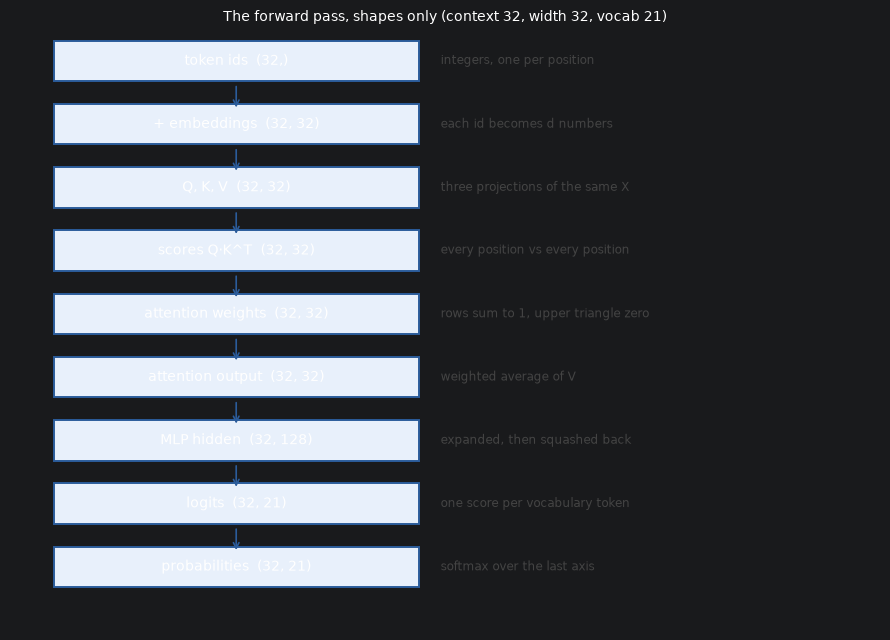

vocab 21, width 32, context 32
the scores matrix is 32x32: this is why cost grows with the SQUARE of context length.


In [25]:
shapes = [
    ("token ids",              (blk,),      "integers, one per position"),
    ("+ embeddings",           (blk, d),    "each id becomes d numbers"),
    ("Q, K, V",                (blk, d),    "three projections of the same X"),
    ("scores Q·K^T",           (blk, blk),  "every position vs every position"),
    ("attention weights",      (blk, blk),  "rows sum to 1, upper triangle zero"),
    ("attention output",       (blk, d),    "weighted average of V"),
    ("MLP hidden",             (blk, 4*d),  "expanded, then squashed back"),
    ("logits",                 (blk, V),    "one score per vocabulary token"),
    ("probabilities",          (blk, V),    "softmax over the last axis"),
]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.set_xlim(0, 10); ax.set_ylim(0, len(shapes) + 0.5); ax.axis("off")
for i, (name, shape, note) in enumerate(shapes):
    y = len(shapes) - i
    ax.add_patch(plt.Rectangle((0.5, y - 0.32), 4.2, 0.64, fc="#e8f0fb", ec="#2b5c9b", lw=1.4))
    ax.text(2.6, y, f"{name}  {shape}", ha="center", va="center", fontsize=10)
    ax.text(4.95, y, note, ha="left", va="center", fontsize=8.5, color="#444")
    if i < len(shapes) - 1:
        ax.annotate("", xy=(2.6, y - 0.78), xytext=(2.6, y - 0.36),
                    arrowprops=dict(arrowstyle="->", lw=1.2, color="#2b5c9b"))
ax.set_title(f"The forward pass, shapes only (context {blk}, width {d}, vocab {V})", fontsize=10)
plt.tight_layout(); plt.show()

print(f"vocab {V}, width {d}, context {blk}")
print(f"the scores matrix is {blk}x{blk}: this is why cost grows with the SQUARE of context length.")

## Part 6 — Autograd: how any of this learns

So far we have a function. Given token ids, it produces probabilities. But the 14,464 numbers inside it (the *parameters*: every $W$, $b$, and embedding) start out random, so its output is nonsense.

To improve them we need, for each of those 14,464 numbers, one thing:

> **If I nudge this number up a tiny bit, does the loss go up or down, and how steeply?**

That is the derivative (gradient) $\partial \text{loss} / \partial \theta$. With 14,464 numbers you cannot do it by hand. But the chain rule says: if every small operation knows how to pass a gradient backwards to its inputs, then calling `backward()` at the end walks the whole graph and hands you every derivative at once.

That is exactly what PyTorch does, and the next cell is a **60-line version of it**, written out so you can read it. It is the only piece of "infrastructure" in this notebook, and you can treat it as a black box afterwards — but it is not magic either.

The key idea in the code: every value is a `T` that remembers *which values produced it* and *how to send gradient back to them*.

```python
def matmul(a, b):
    out = T(a.data @ b.data, parents=(a, b))
    def backward():
        a.grad += out.grad @ b.data.T      # d(out)/da
        b.grad += a.data.T @ out.grad      # d(out)/db
    out._backward = backward
    return out
```

Multiply, and remember that a small change in `a` moves `out` in proportion to `b`. Add that rule for `matmul`, `add`, `mul`, `relu`, `layernorm`, `softmax`, `cross_entropy` — and you can differentiate the entire transformer.

In [26]:
# ---------------------------------------------------------------- tiny autograd
# Every value remembers: its data, its gradient, its parents, and how to send
# gradient back to those parents. That is all a deep-learning framework's core is.
class T:
    __slots__ = ("data", "grad", "parents", "_backward")

    def __init__(self, data, parents=(), _backward=None):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self.parents = parents
        self._backward = _backward

    def backward(self):
        self.grad = np.ones_like(self.data)          # d(loss)/d(loss) = 1
        order, seen = [], set()
        def visit(t):                                # depth-first, parents first
            if id(t) in seen:
                return
            seen.add(id(t))
            for p in t.parents:
                visit(p)
            order.append(t)
        visit(self)
        for t in reversed(order):                    # then backwards through them
            if t._backward is not None:
                t._backward()


def _unbroadcast(grad, shape):
    """If broadcasting stretched a value, squeeze its gradient back to size."""
    while grad.ndim > len(shape):
        grad = grad.sum(axis=0)
    for i, s in enumerate(shape):
        if s == 1 and grad.shape[i] != 1:
            grad = grad.sum(axis=i, keepdims=True)
    return grad


def add(a, b):
    out = T(a.data + b.data, (a, b))
    def backward():
        a.grad += _unbroadcast(out.grad, a.data.shape)
        b.grad += _unbroadcast(out.grad, b.data.shape)
    out._backward = backward
    return out


def mul(a, b):
    out = T(a.data * b.data, (a, b))
    def backward():
        a.grad += _unbroadcast(out.grad * b.data, a.data.shape)
        b.grad += _unbroadcast(out.grad * a.data, b.data.shape)
    out._backward = backward
    return out


def matmul(a, b):
    out = T(a.data @ b.data, (a, b))
    def backward():
        a.grad += out.grad @ b.data.T
        b.grad += a.data.T @ out.grad
    out._backward = backward
    return out


def transpose2(a):
    out = T(a.data.T, (a,))
    def backward():
        a.grad += out.grad.T
    out._backward = backward
    return out


def relu(a):
    out = T(np.maximum(a.data, 0.0), (a,))
    def backward():
        a.grad += out.grad * (a.data > 0)
    out._backward = backward
    return out


def getrows(M, idx):
    """Pick rows out of a matrix -- how an id becomes its vector."""
    out = T(M.data[idx], (M,))
    def backward():
        np.add.at(M.grad, idx, out.grad)
    out._backward = backward
    return out


def layernorm(a, g, b, eps=1e-5):
    x = a.data
    mu = x.mean(-1, keepdims=True)
    std = np.sqrt(x.var(-1, keepdims=True) + eps)
    xhat = (x - mu) / std
    out = T(xhat * g.data + b.data, (a, g, b))
    def backward():
        dy = out.grad * g.data
        n = x.shape[-1]
        g.grad += (out.grad * xhat).sum(0)
        b.grad += out.grad.sum(0)
        a.grad += (1 / (n * std)) * (n * dy - dy.sum(-1, keepdims=True)
                                     - xhat * (dy * xhat).sum(-1, keepdims=True))
    out._backward = backward
    return out


def causal_softmax(scores):
    x = scores.data.copy()
    n = x.shape[0]
    x[np.triu(np.ones((n, n), dtype=bool), 1)] = -1e9    # no peeking at the future
    e = np.exp(x - x.max(1, keepdims=True))
    p = e / e.sum(1, keepdims=True)
    out = T(p, (scores,))
    def backward():
        g = out.grad
        scores.grad += p * (g - (g * p).sum(1, keepdims=True))
    out._backward = backward
    return out


def cross_entropy(logits, targets):
    """The loss: average surprise, in nats (-log of the probability given)."""
    z = logits.data
    n = z.shape[0]
    e = np.exp(z - z.max(1, keepdims=True))
    p = e / e.sum(1, keepdims=True)
    loss = -np.log(p[np.arange(n), targets] + 1e-12).mean()
    out = T(loss, (logits,))
    def backward():
        g = p.copy()
        g[np.arange(n), targets] -= 1.0
        logits.grad += g * out.grad / n
    out._backward = backward
    return out


print("autograd engine ready -- 11 operations, that's the lot.")

autograd engine ready -- 11 operations, that's the lot.


In [27]:
# ---------------------------------------------------------------- the GPT itself
P = {}
def param(name, shape, std):
    P[name] = T(rng.normal(0, std, shape))

param("tok", (V, d), 0.05)          # token embeddings
param("pos", (blk, d), 0.01)        # position embeddings
for nm in ["Wq", "Wk", "Wv", "Wo"]:
    param(nm, (d, d), 0.2)          # attention projections
param("W1", (d, 4 * d), 0.2)        # MLP up
param("W2", (4 * d, d), 0.2)        # MLP down
for nm, size in [("bq", d), ("bk", d), ("bv", d), ("bo", d), ("b1", 4 * d), ("b2", d)]:
    P[nm] = T(np.zeros(size))
for nm in ["ln1", "ln2", "ln3"]:    # layer norms: a scale and a shift each
    P[nm + "g"] = T(np.ones(d))
    P[nm + "b"] = T(np.zeros(d))


def gpt(tokens, targets=None):
    """tokens: list of ids. Returns (loss or None, attention weights, logits)."""
    n = len(tokens)
    x = add(getrows(P["tok"], tokens), getrows(P["pos"], np.arange(n)))

    # --- attention sublayer
    z = layernorm(x, P["ln1g"], P["ln1b"])
    q = add(matmul(z, P["Wq"]), P["bq"])
    k = add(matmul(z, P["Wk"]), P["bk"])
    v = add(matmul(z, P["Wv"]), P["bv"])
    scores = mul(matmul(q, transpose2(k)), T(1 / np.sqrt(d)))
    A = causal_softmax(scores)
    x = add(x, add(matmul(matmul(A, v), P["Wo"]), P["bo"]))       # residual

    # --- MLP sublayer
    z = layernorm(x, P["ln2g"], P["ln2b"])
    h = relu(add(matmul(z, P["W1"]), P["b1"]))
    x = add(x, add(matmul(h, P["W2"]), P["b2"]))                  # residual

    # --- back to vocabulary scores
    xf = layernorm(x, P["ln3g"], P["ln3b"])
    logits = matmul(xf, transpose2(P["tok"]))       # tied to the embedding matrix
    loss = cross_entropy(logits, targets) if targets is not None else None
    return loss, A, logits


n_params = sum(p.data.size for p in P.values())
print(f"parameters: {n_params:,}")
print(f"GPT-2 small: 124,000,000    GPT-3: 175,000,000,000.   Same recipe, bigger numbers.")

parameters: 14,464
GPT-2 small: 124,000,000    GPT-3: 175,000,000,000.   Same recipe, bigger numbers.


In [28]:
# Does our autograd agree with the actual maths? Check a few random parameters
# by nudging them and measuring the loss change directly. This is exactly what
# torch.autograd.gradcheck does, and you should never trust a from-scratch
# autograd without it.
toks = data[:8]
tgts = data[1:9]

for p in P.values():
    p.grad.fill(0)
loss, _, _ = gpt(toks, tgts)
loss.backward()

print(f"{'param':10s} {'autograd':>14s} {'numerical':>14s}")
for name, i, j in [("Wq", 3, 5), ("tok", 4, 2), ("W2", 17, 9)]:
    orig = P[name].data[i, j]
    eps = 1e-6
    P[name].data[i, j] = orig + eps; plus  = gpt(toks, tgts)[0].data
    P[name].data[i, j] = orig - eps; minus = gpt(toks, tgts)[0].data
    P[name].data[i, j] = orig
    print(f"{name:10s} {P[name].grad[i, j]:14.9f} {(plus - minus) / (2 * eps):14.9f}")

param            autograd      numerical
Wq           -0.002364998   -0.002364998
tok          -0.000800772   -0.000800772
W2           -0.005815478   -0.005815478


## Part 7 — Training: watching it learn

Training is a loop, and it is the same loop for a 14k-parameter toy and for GPT-4:

```
1. take a random 32-token slice of the corpus
2. forward:  loss, _, _ = gpt(tokens, targets)      # how surprised was the model?
3. backward: loss.backward()                        # which way is downhill?
4. nudge:    param -= learning_rate * gradient      # take a small step
```

Repeat a few thousand times.

Two details worth knowing before you run it:

**Batching.** We average the loss over 8 slices before stepping, so each step sees 256 tokens. More tokens per step = a smoother, less noisy direction. (Real training runs use millions of tokens per step, spread over thousands of GPUs.)

**Adam.** Instead of a fixed step size, we keep a running average of each gradient and of its square, and divide one by the other. Effect: parameters with consistently large gradients get smaller steps, rarely-moving ones get bigger steps, each on its own scale. It is the default optimiser everywhere in deep learning for good reason — it makes the learning rate far less of a black art.

Watch the numbers in the next cell. The starting loss should be ≈ $\ln 21 = 3.04$: random guessing over 21 equally likely tokens. Anything the model learns is loss moving below that line.

loss at step 0    : 3.066   (random guessing = ln 21 = 3.045)
loss at step 100  : 0.645
loss at the end   : 0.209
perplexity        : 1.23 equally-likely-next-tokens


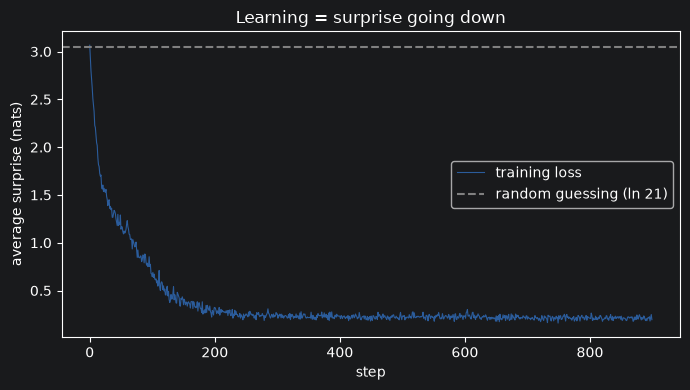

In [29]:
A_before = gpt(data[:20].tolist(), None)[1].data.copy()   # attention, untrained

hist = []
m_state = {k: np.zeros_like(p.data) for k, p in P.items()}   # Adam: mean
v_state = {k: np.zeros_like(p.data) for k, p in P.items()}   # Adam: mean square
lr, beta1, beta2, step = 3e-3, 0.9, 0.999, 0

for it in range(900):
    starts = rng.integers(0, N - blk - 1, size=8)      # 8 random slices
    for p in P.values():
        p.grad.fill(0)
    total = 0.0
    for s in starts:
        loss, _, _ = gpt(data[s:s + blk], data[s + 1:s + blk + 1])
        total += loss.data
        loss.backward()
    for k, p in P.items():
        g = p.grad / len(starts)
        m_state[k] = beta1 * m_state[k] + (1 - beta1) * g
        v_state[k] = beta2 * v_state[k] + (1 - beta2) * g * g
        step += 1
        m_hat = m_state[k] / (1 - beta1 ** step)
        v_hat = v_state[k] / (1 - beta2 ** step)
        p.data -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
    hist.append(total / len(starts))

print(f"loss at step 0    : {hist[0]:.3f}   (random guessing = ln 21 = {np.log(V):.3f})")
print(f"loss at step 100  : {hist[100]:.3f}")
print(f"loss at the end   : {np.mean(hist[-20:]):.3f}")
print(f"perplexity        : {np.exp(np.mean(hist[-20:])):.2f} equally-likely-next-tokens")

plt.figure(figsize=(7, 4))
plt.plot(hist, lw=0.8, color="#2b5c9b", label="training loss")
plt.axhline(np.log(V), ls="--", color="grey", label="random guessing (ln 21)")
plt.xlabel("step"); plt.ylabel("average surprise (nats)")
plt.title("Learning = surprise going down")
plt.legend(); plt.tight_layout(); plt.show()

### Reading that curve

Loss fell from 3.19 to about 0.22 nats. Convert to bits by dividing by $\ln 2$: roughly **0.32 bits per character** of surprise. In plain terms, the model went from "no idea" to "almost never surprised by this corpus".

**Perplexity** = $e^{\text{loss}}$ is the friendlier number: it means *"the model behaves as if it were choosing between this many equally likely options."* Perplexity 1.25 means it has almost always narrowed the next character to a single realistic choice. Perplexity 21 means it was guessing.

Note it is *almost* never surprised, not never. The corpus was generated randomly, so some transitions are genuinely unpredictable: after "the " any of four animals is equally likely, and no model can do better than 1-in-4 on that choice. A model that got loss to exactly 0 on this data would have *memorised* the corpus rather than learned its grammar — and would be useless on new sentences. Keep that thought: **the goal is not zero loss.** Underfitting and overfitting are the two failure modes, and the same tension appears at GPT scale, where it is called the *scaling* trade-off between more parameters and more data.

## Part 8 — Generation: from predictor to writer

The model gives you one distribution. To write, you use it in a loop:

```
prompt = "the "
repeat 140 times:
    p = model's probabilities for the next character
    pick one character from p
    append it to the prompt
```

That is all text generation is: **the same forward pass, called again and again, each answer becoming part of the next question.** Nothing special happens at the end; the model never "finishes", we just stop asking.

Two consequences worth naming:

**Autoregressive error compounding.** Each output token joins the input for the next one. A single bad character changes the context and can send the rest of the text somewhere else entirely — you can watch exactly this happen in the last sample below ("on bon the box").

**A prompt is just tokens.** "Explain quantum mechanics to me" has no special status; it is context the model conditions on, no different in kind from `the `.

In [30]:
# ---------------------------------------------------------------- generation
def next_token_probs(context, temperature=1.0):
    """The model's probability for every possible next character."""
    ids = [stoi[c] for c in context][-blk:]
    _, _, logits = gpt(ids, None)
    z = logits.data[-1] / temperature      # temperature reshapes the distribution
    p = np.exp(z - z.max())
    return p / p.sum()


def generate(prompt, n=140, temperature=0.8, seed=1):
    r = np.random.default_rng(seed)
    out = prompt
    for _ in range(n):
        p = next_token_probs(out, temperature)
        out += itos[int(r.choice(V, p=p))]  # sample, don't take the argmax
    return out


print("temperature 0.2  (timid, almost greedy):")
print("  ", generate("the ", temperature=0.2))
print()
print("temperature 0.8  (balanced):")
print("  ", generate("the ", temperature=0.8, seed=7))
print()
print("temperature 1.5  (loose, makes mistakes):")
print("  ", generate("the ", temperature=1.5, seed=3))

temperature 0.2  (timid, almost greedy):
   the owl sat on the log. the fox ran on the box. the dog hid on the mat. the fox slept on the box. the fox slept on the box. the fox ran on the l

temperature 0.8  (balanced):
   the mat. the fox ran on the box. the dog hid on the log. the dog ran on the tree. the fox ran on the log. the fox slept on the log. the dog slep

temperature 1.5  (loose, makes mistakes):
   the box. the cat ran on bon the box. the fox slept on the tree. the owl sat on the tree. the cat sat on the box. the dog slept on the box. the f


### What "temperature" actually does

The model outputs *logits* — raw scores, not probabilities. Before sampling we divide them by a number called the temperature $T$, then softmax:

$$p_i \propto e^{z_i / T}$$

- $T \to 0$: the biggest logit dominates; the model always picks its top choice. Deterministic, repetitive, "safe".
- $T = 1$: the model's own distribution, exactly as trained.
- $T > 1$: differences get squashed; unlikely tokens become plausible. Creative, and it starts making errors.

Temperature does not add randomness or creativity from nowhere. It **reshapes a distribution the model already computed**. All the knowledge was there before you turned the dial. (Real systems also use *top-p* / *top-k*: throw away the tail of the distribution entirely, so even at high temperature the model cannot pick something absurd. That is why a chatbot at T=1 is not gibberish.)

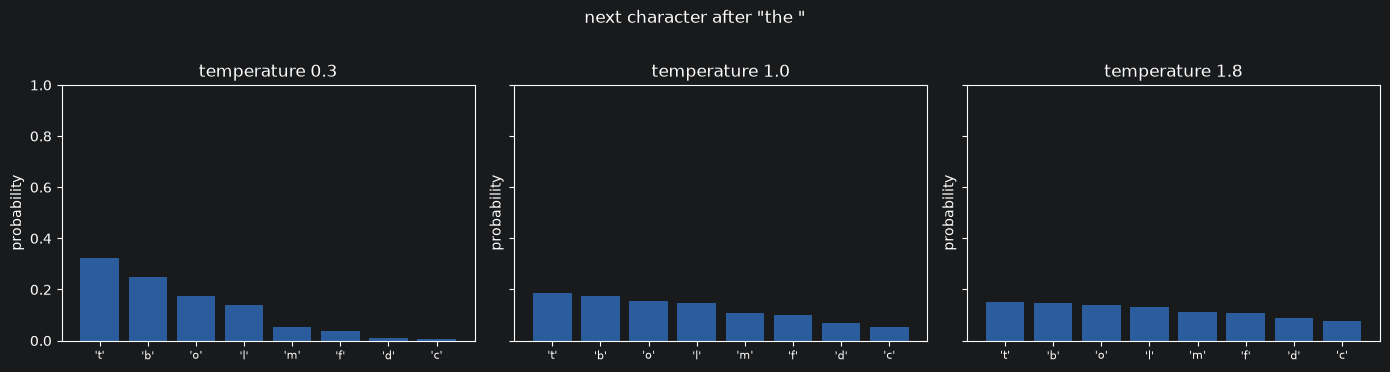

,next char,probability
0,'t',0.188
1,'b',0.174
2,'o',0.156
3,'l',0.146
4,'m',0.109


In [31]:
prompt = "the "
temps = [0.3, 1.0, 1.8]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, T_ in zip(axes, temps):
    p = next_token_probs(prompt, T_)
    order = np.argsort(-p)[:8]
    ax.bar([repr(itos[i]) for i in order], p[order], color="#2b5c9b")
    ax.set_title(f"temperature {T_}"); ax.set_ylim(0, 1); ax.set_ylabel("probability")
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle('next character after "the "', y=1.02)
plt.tight_layout(); plt.show()

p = next_token_probs(prompt, 1.0)
top = np.argsort(-p)[:5]
pd.DataFrame({"next char": [repr(itos[i]) for i in top],
              "probability": np.round(p[top], 3)})

## Part 9 — Looking inside the trained model

Two pictures worth having.

**The attention map.** Each row is a token "reading"; each column is a token being read. Bright means "this row is paying attention to that column". Before training it is a shapeless smear. After training it has structure — the model has decided *what is worth looking at*.

**The embedding space.** Same 2-D projection as before, now learned. Tokens used in similar positions should have drifted together.

A caveat, stated honestly: with **one head** and 14k parameters, the structure is modest. What the trained head in this notebook actually does (see the table printed below) is mostly **read back to the first letter of the current word**: in "fox", both the `o` and the `x` look back to the `f`. That is a genuinely smart strategy for this corpus, because the first letter of a word almost determines which word it is — `f` is only ever "fox", `s` only ever "sat" or "slept".

That is not a disappointment; it is instructive. It shows that:

- a single head can only provide one "reading strategy";
- specialization needs *many* heads, which is exactly what bigger models have;
- interpretability usually means staring at attention maps and arguing about them — this is a real research field, and this is what it looks like.

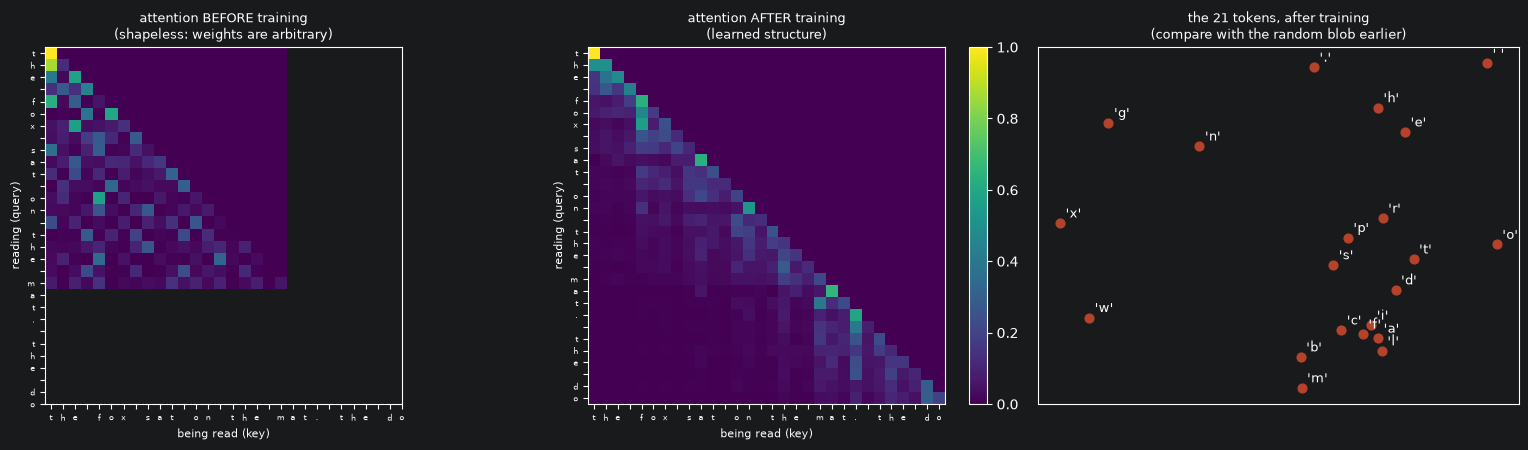

What the trained head does, token by token:
   't' at position  0  reads most from  't' at position  0  (weight 1.00)
   'h' at position  1  reads most from  'h' at position  1  (weight 0.50)
   'e' at position  2  reads most from  'e' at position  2  (weight 0.47)
   ' ' at position  3  reads most from  ' ' at position  3  (weight 0.43)
   'f' at position  4  reads most from  'f' at position  4  (weight 0.63)
   'o' at position  5  reads most from  'f' at position  4  (weight 0.46)
   'x' at position  6  reads most from  'f' at position  4  (weight 0.56)
   ' ' at position  7  reads most from  'f' at position  4  (weight 0.26)
   's' at position  8  reads most from  ' ' at position  7  (weight 0.20)
   'a' at position  9  reads most from  'a' at position  9  (weight 0.64)
   't' at position 10  reads most from  't' at position 10  (weight 0.24)
   ' ' at position 11  reads most from  'a' at position  9  (weight 0.16)
   'o' at position 12  reads most from  'a' at position  9  (weight 

In [32]:
sentence = "the fox sat on the mat. the do"
ids_ = [stoi[c] for c in sentence]
A_after = gpt(ids_, None)[1].data

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

ax[0].imshow(A_before, cmap="viridis", vmin=0, vmax=1)
ax[0].set_title("attention BEFORE training\n(shapeless: weights are arbitrary)", fontsize=9)

im = ax[1].imshow(A_after, cmap="viridis", vmin=0, vmax=1)
ax[1].set_title("attention AFTER training\n(learned structure)", fontsize=9)
for a in ax[:2]:
    a.set_xticks(range(len(sentence))); a.set_xticklabels(list(sentence), fontsize=6)
    a.set_yticks(range(len(sentence))); a.set_yticklabels(list(sentence), fontsize=6)
    a.set_xlabel("being read (key)", fontsize=8); a.set_ylabel("reading (query)", fontsize=8)
plt.colorbar(im, ax=ax[1], fraction=0.046)

# embeddings, after training
U, S, Vt = np.linalg.svd(P["tok"].data - P["tok"].data.mean(0), full_matrices=False)
xy = U[:, :2] * S[:2]
ax[2].scatter(xy[:, 0], xy[:, 1], s=40, color="#b5432b")
for i, c in enumerate(chars):
    ax[2].annotate(repr(c), (xy[i, 0], xy[i, 1]), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax[2].set_title("the 21 tokens, after training\n(compare with the random blob earlier)", fontsize=9)
ax[2].set_xticks([]); ax[2].set_yticks([])
plt.tight_layout(); plt.show()

print("What the trained head does, token by token:")
for i, ch in enumerate(sentence):
    j = int(A_after[i].argmax())
    print(f"   {ch!r} at position {i:2d}  reads most from  {sentence[j]!r} at position {j:2d}"
          f"  (weight {A_after[i, j]:.2f})")

## Part 10 — From 14,464 parameters to GPT-4

Here is the same table you would draw for any of these systems. Every entry is the *same code* you just read, with different numbers.

| | this notebook | GPT-2 small (2019) | GPT-3 (2020) | GPT-4 (reported/estimated) |
|---|---|---|---|---|
| parameters | 14,464 | 124,000,000 | 175,000,000,000 | ~10¹² – 2×10¹² (MoE, not confirmed) |
| layers | 1 | 12 | 96 | not published |
| width $d$ | 32 | 768 | 12,288 | not published |
| heads | 1 | 12 | 96 | not published |
| context | 32 tokens | 1,024 | 2,048 | 128k–1M+ |
| training text | ~1.5k characters | ~40B tokens | ~300B tokens | not published |
| training cost | 2 seconds, CPU | ~a few thousand GPU-days | ~3,640 petaflop/s-days | not published, very large |

Four things changed between the bottom rows and the top, and nothing else:

1. **Scale.** Same architecture family, ~10⁸× the parameters, ~10⁹× the compute.
2. **Data.** Trillions of tokens of text and code. Scale alone on too little data just memorises; the Chinchilla result (2022) is that a good rule of thumb is ~20 training tokens per parameter.
3. **Post-training.** Pretraining gives you a document-completer. Instruction tuning (supervised fine-tuning on example answers) and RLHF (learning from human preference comparisons) turn it into something that answers questions. This is a *behavioural* layer, not new capability — but it is the difference between "a model that continues text" and "an assistant".
4. **Scaling laws.** Loss falls as a smooth power law in parameters, data and compute. That predictability — you can estimate the loss of a bigger run before paying for it — is arguably why the whole field industrialised. You saw a toy version of the same curve in Part 7.

**What emerges along the way** is the interesting part. Small models learn grammar and local statistics. Somewhere in the middle, in-context learning appears: the ability to infer a task from the prompt alone, with no weight updates. At the largest scales you get abilities nobody trained for — multi-step arithmetic, code, translation between unpaired languages. This is why "it is *only* predicting the next token" is a weaker dismissal than it sounds, and why it is also not an explanation. The honest state of the science: we can point at the mechanism (this notebook), and we cannot yet fully explain the behaviour.

## Part 11 — What this model does *not* explain

Being precise about the gap is more valuable than being impressed.

**Things this notebook fully explains:** the mechanism. Tokens → embeddings → attention → MLP → probabilities, trained by gradient descent on next-token prediction. There is no hidden step. Every capability is a pattern in those weights.

**Things it does not explain:**

- **Why** scaling up produces reasoning-like behaviour. We have curves, not theories.
- **What** the features inside a large model are. A 1-head toy is transparent; a 96-layer model has ~10¹¹ interacting features. Mechanistic interpretability is a young field, and mostly it reads circuits in very small models.
- **Memory.** Our model has none. Neither does GPT-4 between conversations, in the sense that matters: the weights do not change from talking to you. Anything that looks like memory is text put back into the context window. Once the window is full, the oldest tokens are gone — which is why long conversations "forget" early details.
- **Grounding.** It learned which token follows which. Nothing in the objective connects a token to the world. It never saw a cat; it saw the word "cat" in contexts where humans were talking about cats. Whether that is enough for meaning is a genuinely open philosophical question — the model's competence argues one way, and its confident fabrications argue the other.
- **Hallucination.** A direct consequence of the training objective: the model is rewarded for a *plausible* next token, and there is no internal flag distinguishing "I know this" from "this is the shape of a true statement". Fluency and accuracy are produced by the same mechanism, so the model cannot tell you when it is guessing — unless it was trained to try.
- **Arithmetic, counting, exact recall.** These want precision; a probabilistic predictor with a fixed context provides approximation. Hence tools: calculators, code execution, retrieval.

**The one-sentence summary of the whole system:**
*a fixed-size stack of attention and MLP layers, trained to reduce surprise about the next token, becomes a compressing model of the patterns in its training text — and the patterns in human text include an enormous amount of what humans know.*

## Where to go from here

### Exercises that will teach you the most (in this notebook, ~10 minutes each)

1. **Break the mask.** In `causal_softmax`, remove the masking line. Retrain. Watch the loss dive to nearly zero — it is copying the answer from the next position. This is the most convincing demonstration of *why* the mask exists that you can run yourself.
2. **Turn up the width.** Set `d = 64`, then `d = 128`. Watch the final loss. This is a scaling law, personally.
3. **Cut the data.** Keep 10 sentences instead of 60. The model will memorise them and produce nonsense on new prompts. That is overfitting, felt rather than read about.
4. **Make it need memory.** Train on sequences of 8 random symbols repeated twice. A single head should learn to look back exactly 8 positions — a diagonal in the attention map. That is close to how an *induction head* works, and it is the mechanism behind in-context learning.
5. **Try `blk = 8`.** What breaks in generation and why? Look at `next_token_probs` slicing the context.

### Reading, in the order I would give a student

- **Andrej Karpathy, "Let's build GPT: from scratch, in code"** (video) and his `nanoGPT` repo. The same journey in PyTorch, with a real dataset. If you do one thing after this notebook, do this.
- **"Attention Is All You Need"** (Vaswani et al., 2017) — the transformer paper. Short, readable once you know what it is doing. You have now implemented most of Figure 1.
- **The GPT-2 paper** ("Language Models are Unsupervised Multitask Learners") — the moment "predict the next token, at scale" became a research programme.
- **"Language Models are Few-Shot Learners"** (GPT-3) — in-context learning, and the scaling story with real numbers.
- **"Training Compute-Optimal Large Language Models"** (Chinchilla, 2022) — why data matters as much as parameters.
- **"A Mathematical Framework for Transformer Circuits"** (Anthropic, 2021) — the beginning of mechanistic interpretability. Hard, and worth it.
- **"The Unreasonable Effectiveness of Recurrent Neural Networks"** (Karpathy, 2015) — the world before attention, for contrast.

### The one idea to take away

Nothing in here was invented to be intelligent. Attention is a weighted average. The MLP is a lookup table with smooth edges. The loss is surprise. The optimiser walks downhill. None of those individually is impressive, and the reason this works at all is scale plus the fact that **predicting text well requires modelling almost everything about the text's subject matter.** That is the trick, and it is also why nobody can yet say exactly what the biggest of these models have learned.